In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
import pmxt

In [2]:
poly = pmxt.Polymarket()

In [3]:
events = poly.fetch_events(query="(MSFT) closes week of Mar 2 at ")

In [4]:
event = events[0]

<BarContainer object of 11 artists>

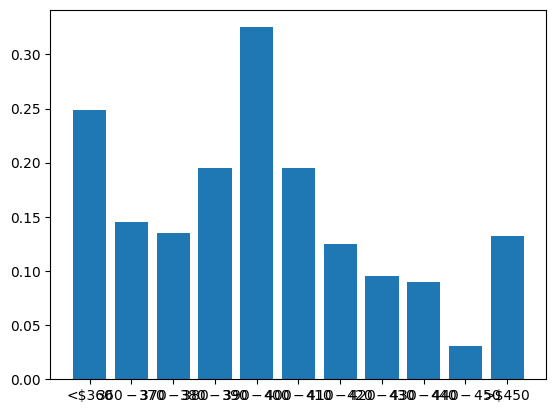

In [5]:
outcomes = sorted([m.yes for m in event.markets], key=lambda o: [x for x in o.label if x in "0123456789"])
prices = np.array([o.price for o in outcomes])

plt.bar([o.label for o in outcomes], prices)

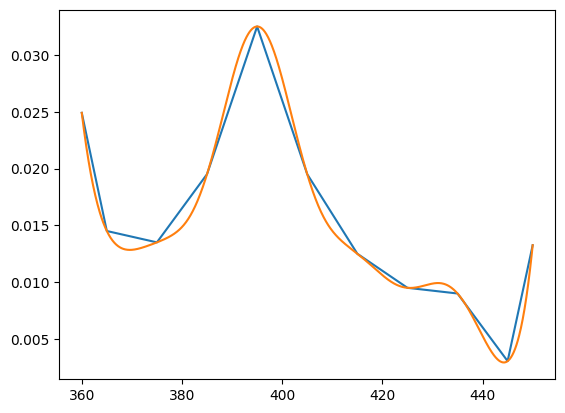

In [6]:
mid_points = []
for o in outcomes:
    if any(c in "><" for c in o.label):
        mid_points += [int(o.label[2:])]
    else:
        mid_points += [(sum(int(x) for x in o.label[1:].split("-$")))/2]

plt.plot(mid_points, prices/10)
outcome_space = np.linspace(mid_points[0], mid_points[-1], 1000)
interp_pdf = scipy.interpolate.make_splrep(mid_points, prices, k=4)(outcome_space)/10
plt.plot(outcome_space, interp_pdf) 

In [7]:
r = 0.05


In [8]:
def log_normal_pdf(x, mu, sigma):
    return (1/(x * sigma * np.sqrt(2 * np.pi)))*np.exp(-((np.log(x)-mu)**2/(2*sigma**2)))

def returns_distribution(s, sigma, r, T, S0):
    return (1/(s*sigma*np.sqrt(2*np.pi*T)))*np.exp(-((np.log(s/S0)-(r-sigma**2/2)*T)**2)/(2*(sigma**2)*T))

In [9]:
(sigma,), cov = scipy.optimize.curve_fit(lambda x, sigma: returns_distribution(x, sigma, r, T, current_price), outcome_space, interp_pdf, p0=[np.log(400), 0.01])

TypeError: <lambda>() takes 2 positional arguments but 3 were given

In [ ]:
plt.plot(mid_points, prices/10)
plt.plot(outcome_space, log_normal_pdf(outcome_space, sigma, r, T, current_price))

In [ ]:
mu,sigma

In [ ]:
np.exp(mu)

In [ ]:
from predictlib import *